# Indiana University Chest X-Ray Dataset: Exploratory Data Analysis & Pipeline

>**Project Overview**
> This project implements a complete end-to-end multimodal model pipeline on the **Indiana University Chest X-Ray DataSet. The architecture starts from data auditing, Exploratory Data analysis, Data preprocessing pipeline, Computer vision and natural langauge processing.

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import seaborn as sb
import string
import re
import hashlib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import tensorflow as tf
from tensorflow import keras
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer, PorterStemmer
from transformers import AutoTokenizer
from sklearn.preprocessing import MultiLabelBinarizer
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import DenseNet121

## Data Exploring

In [59]:
df = pd.read_csv('/kaggle/input/datasets/raddar/chest-xrays-indiana-university/indiana_reports.csv')
images_df = pd.read_csv('/kaggle/input/datasets/raddar/chest-xrays-indiana-university/indiana_projections.csv')
image_folder  = Path("/kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized")
df.head()


,uid,MeSH,Problems,image,indication,comparison,findings,impression
0,1,normal,normal,Xray Chest PA and Lateral,Positive TB test,None.,The cardiac silhouette and mediastinum size ar...,Normal chest x-XXXX.
1,2,Cardiomegaly/borderline;Pulmonary Artery/enlarged,Cardiomegaly;Pulmonary Artery,"Chest, 2 views, frontal and lateral",Preop bariatric surgery.,None.,Borderline cardiomegaly. Midline sternotomy XX...,No acute pulmonary findings.
2,3,normal,normal,Xray Chest PA and Lateral,"rib pain after a XXXX, XXXX XXXX steps this XX...",NaN,NaN,"No displaced rib fractures, pneumothorax, or p..."
3,4,"Pulmonary Disease, Chronic Obstructive;Bullous...","Pulmonary Disease, Chronic Obstructive;Bullous...","PA and lateral views of the chest XXXX, XXXX a...",XXXX-year-old XXXX with XXXX.,None available,There are diffuse bilateral interstitial and a...,1. Bullous emphysema and interstitial fibrosis...
4,5,Osteophyte/thoracic vertebrae/multiple/small;T...,Osteophyte;Thickening;Lung,Xray Chest PA and Lateral,Chest and nasal congestion.,NaN,The cardiomediastinal silhouette and pulmonary...,No acute cardiopulmonary abnormality.


In [60]:
df.shape

(3851, 8)

In [61]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3851 entries, 0 to 3850
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   uid         3851 non-null   int64 
 1   MeSH        3851 non-null   object
 2   Problems    3851 non-null   object
 3   image       3851 non-null   object
 4   indication  3765 non-null   object
 5   comparison  2685 non-null   object
 6   findings    3337 non-null   object
 7   impression  3820 non-null   object
dtypes: int64(1), object(7)
memory usage: 240.8+ KB


## Categorical column representation 

- **Column:** `MeSH`  
  **Name:** `Medical subject headings`  
  **Description:** `Medical vocabulary to describe medical concepts consistently`  
  
- **Column:** `Problem`  
  **Description:** `Demonstrates medical findings for each patient report`  

- **Column:** `image`  
  **Description:** `Describes the title of the images used for the report`  

- **Column:** `Indication`  
  **Description:** `The clinical reason that Urged the patient to do the Chest X-ray`  

- **Column:** `Comparison`  
  **Description** ` Information about previous imaging and x-ray the Doctor used to compare with the current examination images and x-rays`  

- **Column:** `Findings`  
  **Description** `Contains the detailed description of what the doctor observes during the x-ray`  

- **Column:** `Impression`  
  **Description:** `Contains the summary of the important conclusion drawn from the findings`  

- **Column:** `Projection`
  **Description:** `Describes the anatomical view or orientation angle of the X-ray image (Frontal / Lateral)`

- **Column** `Filename`
  **Description:** `The location of the Image in the Images Folder`

  

In [62]:
columns  = df.columns
for column in columns:
    print("-"*50)
    print(f"Column: {column}")
    print(f"Number of unique entries: {df[column].nunique()}")

--------------------------------------------------
Column: uid
Number of unique entries: 3851
--------------------------------------------------
Column: MeSH
Number of unique entries: 1900
--------------------------------------------------
Column: Problems
Number of unique entries: 1432
--------------------------------------------------
Column: image
Number of unique entries: 697
--------------------------------------------------
Column: indication
Number of unique entries: 2454
--------------------------------------------------
Column: comparison
Number of unique entries: 393
--------------------------------------------------
Column: findings
Number of unique entries: 2553
--------------------------------------------------
Column: impression
Number of unique entries: 1770


In [63]:
columns  = df.columns
for column in columns:
    print("-"*50)
    print(f"Column: {column}")
    print(f"First 10 unique entries: {df[column].value_counts(dropna = False).head(5)}")

--------------------------------------------------
Column: uid
First 10 unique entries: uid
3999    1
1       1
2       1
3       1
4       1
Name: count, dtype: int64
--------------------------------------------------
Column: MeSH
First 10 unique entries: MeSH
normal                                  1379
No Indexing                               92
Lung/hypoinflation                        44
Thoracic Vertebrae/degenerative/mild      29
Thoracic Vertebrae/degenerative           23
Name: count, dtype: int64
--------------------------------------------------
Column: Problems
First 10 unique entries: Problems
normal                 1379
No Indexing              92
Lung                     86
Calcified Granuloma      84
Thoracic Vertebrae       59
Name: count, dtype: int64
--------------------------------------------------
Column: image
First 10 unique entries: image
Xray Chest PA and Lateral                           1218
CHEST 2V FRONTAL/LATERAL                              92
Chest, 2 

## Images Table Exploring

In [64]:
print(images_df.shape)

print(images_df.info())

images_df.head()


(7466, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7466 entries, 0 to 7465
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   uid         7466 non-null   int64 
 1   filename    7466 non-null   object
 2   projection  7466 non-null   object
dtypes: int64(1), object(2)
memory usage: 175.1+ KB
None


,uid,filename,projection
0,1,1_IM-0001-4001.dcm.png,Frontal
1,1,1_IM-0001-3001.dcm.png,Lateral
2,2,2_IM-0652-1001.dcm.png,Frontal
3,2,2_IM-0652-2001.dcm.png,Lateral
4,3,3_IM-1384-1001.dcm.png,Frontal


In [65]:
images_per_id = images_df.groupby("uid").size()

print("IDs that correspond to two images: ", (images_per_id==2).sum())
      
print("IDs that correspond to less than two images: ", (images_per_id<2).sum())
      
print("IDs that correspond to more than two images: ", (images_per_id>2).sum())
      
print("Image_distribution: \n", images_per_id.value_counts())

IDs that correspond to two images:  3210
IDs that correspond to less than two images:  446
IDs that correspond to more than two images:  195
Image_distribution: 
 2    3210
1     446
3     181
4      13
5       1
Name: count, dtype: int64


In [66]:
fewer_than_two = images_per_id[images_per_id < 2]

more_than_two = images_per_id[images_per_id>2]

print(more_than_two.head(5))

print(fewer_than_two.head(5))

uid
42    3
62    3
77    3
78    3
80    3
dtype: int64
uid
44    1
45    1
60    1
68    1
71    1
dtype: int64


## Data quality assessment

### Text normalization

In [67]:
df_clean = df.copy()

text_columns = df_clean.select_dtypes(include = ["object", "string"])

missing_values = ['none','nan','none.','none available','n/a','na','null','','xxxx','xxxx, xxxx.','xxxx, xxxx','xxxx.']

for column in text_columns: 
    df_clean[column] = (df_clean[column].astype('string').str.strip().str.lower().str.replace(r"\s+", " ", regex=True))

### Removing Punctuation

In [68]:
def remove_punctuation(text):
    if isinstance(text, str):
        text = text.translate(str.maketrans('', '', string.punctuation))
        return text


In [69]:
medical_text_columns = ['indication', 'findings', 'impression']
for col in medical_text_columns:
    df_clean[col] = df_clean[col].apply(remove_punctuation)

### Checking amount of Null entries in each feature in the report

In [70]:
for column in text_columns: 
    
    df_clean[column] = df_clean[column].mask(df_clean[column].isin(missing_values))
    
missing_counts = df_clean.isna().sum()

missing_percentages = (df_clean.isna().sum()/len(df_clean))*100

missing_summary = pd.DataFrame(
    {
        'missing_values': missing_counts,
        'missing_percentage': missing_percentages.round(2)
    }
)
missing_summary

,missing_values,missing_percentage
uid,0,0.00
MeSH,0,0.00
Problems,0,0.00
image,1,0.03
indication,262,6.80
comparison,2860,74.27
findings,514,13.35
impression,31,0.80


### Dealing with Image null value

In [71]:
image_row_missing = df_clean[df_clean['image'].isnull()]
image_row_missing 


,uid,MeSH,Problems,image,indication,comparison,findings,impression
3795,3943,calcinosis/lung/hilum/left,calcinosis,<NA>,chest pain,<NA>,the bony thorax is intact and the heart size i...,negative chest


#### Checking the ID in the image_table

In [72]:
image_missing = images_df[images_df["uid"] == 3943]
image_missing

,uid,filename,projection
7352,3943,3943_IM-2013-1001.dcm.png,Frontal


### Retype manually to Chest Frontal 
> As we found that the only Null value is actually not null but is actually a frontal image

In [73]:
df_clean['image'] = df_clean['image'].fillna('Chest Frontal')
image_row_missing = df_clean[df_clean['image'].isnull()]
image_row_missing

,uid,MeSH,Problems,image,indication,comparison,findings,impression


### Replacing null values with No history in Comparison Column

In [74]:
df_clean["comparison"] = df_clean["comparison"].fillna("No history")
# Validate that there are no Zeroes Left
df_clean["comparison"].isna().sum()

np.int64(0)

### For other Null variables:
> Null values in Indication, Findings, Impression cannot be Filled directly As There is no indication on what to fill them with and This Risks losing information
> Therefore for now to not hinder NLP model each NaN is going to be replaced with not provided

In [75]:
df_clean[medical_text_columns] = df_clean[medical_text_columns].fillna('not provided')
df_clean.isna().sum()

uid           0
MeSH          0
Problems      0
image         0
indication    0
comparison    0
findings      0
impression    0
dtype: int64

### Checking XXXX string in text features
> The xxxx are a result of censoring medical pateint information from the dataset, therefore it might hold value but if they are the only in one line then we cant take any value from them

#### XXXX placeholder count in each column

In [76]:
for column in text_columns:
    contains_xxxx = df_clean[column].str.contains(r"(?i)\bxxxx\b", na = False, regex = True)
    print(f" {column} entries containing xxxx in it: {contains_xxxx.sum()}")
    

 MeSH entries containing xxxx in it: 0
 Problems entries containing xxxx in it: 0
 image entries containing xxxx in it: 2023
 indication entries containing xxxx in it: 1321
 comparison entries containing xxxx in it: 819
 findings entries containing xxxx in it: 1416
 impression entries containing xxxx in it: 593


### Replace XXXX with Hidden
> Replace the censored string with hidden to know its meaning

In [77]:
for column in text_columns:
  df_clean[column] = df_clean[column].astype("string").str.replace(r"(?i)xxxx", "hidden", regex=True)
    
  contains_xxxx = df_clean[column].str.contains(r"(?i)\bxxxx\b", na = False, regex = True)
    
  print(f" {column} entries containing xxxx in it: {contains_xxxx.sum()}")

 MeSH entries containing xxxx in it: 0
 Problems entries containing xxxx in it: 0
 image entries containing xxxx in it: 0
 indication entries containing xxxx in it: 0
 comparison entries containing xxxx in it: 0
 findings entries containing xxxx in it: 0
 impression entries containing xxxx in it: 0


> However there is still a problem: entries like : xxxx year old patient with xxxx hold no information, however will not be detected and can be feeded into our model, therefore the xxxx string requires further cleaning

#### Function to identify non informative statements

In [78]:
def flag_non_informative(text):
    if pd.isna(text) or not isinstance(text, str):
        return "not provided"
    cleaned = re.sub(r'\b(hiddenyearold|hiddenyearsold|yearold|yearsold|male|female|patient)\b', '', text)
    cleaned = re.sub(r'\s+', ' ', cleaned).strip()
    words_without_hidden = cleaned.replace('hidden', '').strip()
    
    if len(words_without_hidden) == 0 or words_without_hidden in ['with', 'old', 'year', 'and', 'or']:
        return "not provided"
    return text

#### Apply the function

In [79]:
for column in text_columns: 
    df_clean[column] = df_clean[column].astype('string').apply(flag_non_informative)
df_clean.head(10)

,uid,MeSH,Problems,image,indication,comparison,findings,impression
0,1,normal,normal,xray chest pa and lateral,positive tb test,No history,the cardiac silhouette and mediastinum size ar...,normal chest hiddenx
1,2,cardiomegaly/borderline;pulmonary artery/enlarged,cardiomegaly;pulmonary artery,"chest, 2 views, frontal and lateral",preop bariatric surgery,No history,borderline cardiomegaly midline sternotomy hid...,no acute pulmonary findings
2,3,normal,normal,xray chest pa and lateral,rib pain after a hidden hidden hidden steps th...,No history,not provided,no displaced rib fractures pneumothorax or ple...
3,4,"pulmonary disease, chronic obstructive;bullous...","pulmonary disease, chronic obstructive;bullous...","pa and lateral views of the chest hidden, hidd...",not provided,No history,there are diffuse bilateral interstitial and a...,1 bullous emphysema and interstitial fibrosis ...
4,5,osteophyte/thoracic vertebrae/multiple/small;t...,osteophyte;thickening;lung,xray chest pa and lateral,chest and nasal congestion,No history,the cardiomediastinal silhouette and pulmonary...,no acute cardiopulmonary abnormality
5,6,normal,normal,"pa and lateral chest. hidden, hidden at hidden",evaluate for infection,No history,heart size and mediastinal contour are within ...,no acute cardiopulmonary findings
6,7,pulmonary atelectasis/base;spondylosis/thoraci...,pulmonary atelectasis;spondylosis;arthritis,xray chest pa and lateral,preop lumbar surgery,No history,the cardiac contours are normal hidden basilar...,basilar atelectasis no confluent lobar consoli...
7,8,normal,normal,xray chest pa and lateral,hiddenyearold with hidden on hidden dyspnea hi...,two views of the chest dated hidden.,the heart pulmonary hidden and mediastinum are...,no acute cardiopulmonary disease
8,9,calcified granuloma/lung/upper lobe/right;dens...,calcified granuloma;density,xray chest pa and lateral,chest pain today history of stent placement 7 ...,"ct hidden image hidden, ct abdomen which inclu...",the hidden examination consists of frontal and...,increased size of density in the left cardioph...
9,10,calcified granuloma/lung/upper lobe/right,calcified granuloma,pa and lateral chest x-hidden hidden.,hiddenyearold male chest pain,chest radiographs hidden.,the cardiomediastinal silhouette is within nor...,no acute cardiopulmonary process


### Drop comparison column as 70% is not provided

In [80]:
df_clean.drop(columns=["comparison"], inplace=True)

### Checking for duplicated entries

In [81]:
duplicated_rows = df_clean.duplicated().sum()
print("duplicated rows: ", duplicated_rows)

duplicated rows:  0


## Exploring the Projections and Images Files

### Checking ID to images cardinality

In [82]:
report_ids  = set(df["uid"])
images_ids = set(images_df["uid"])
print(len(report_ids))
print(len(images_ids))
print("Report IDs without Image IDs: ",len((report_ids - images_ids)))

3851
3851
Report IDs without Image IDs:  0


### Check for duplicated rows in projections data
> This checks duplication of image filenames however not the images themselves

In [83]:
print("Duplicated rows: ", images_df.duplicated().sum())

Duplicated rows:  0


## Exploring the Images 

### Opening The Image folder

In [84]:
print("Folder exists:", image_folder.exists())

if image_folder.exists():
    first_image = next(image_folder.iterdir(), None)
    print("First image:", first_image)

Folder exists: True
First image: /kaggle/input/datasets/raddar/chest-xrays-indiana-university/images/images_normalized/1000_IM-0003-1001.dcm.png


### Create an image_info dataframe to apply analysis 

In [85]:
image_info = []
for filename in tqdm(images_df["filename"].dropna(), desc = "Processing All Images"):
    path = image_folder/filename
    
    if not path.is_file():
        
        continue
    try:
        
        with Image.open(path) as img:
            # img_array = np.array(img)
            image_info.append({
                "filename" : filename, 
                "width" : img.width,
                "height" : img.height,
                "mode" : img.mode,
                "format" : img.format,
                # "min_pixel":img_array.min(),
                # "max_pixel":img_array.max()
            })
    except:
            image_info.append({
                "filename" : filename, 
                "width" : None,
                "height" : None,
                "mode" : None,
                "format" : None,
                # "min_pixel":None,
                # "max_pixel":None
            }                   
                              
            )
image_info_df = pd.DataFrame(image_info)


Processing All Images: 100%|██████████| 7466/7466 [00:05<00:00, 1250.54it/s]


In [86]:
image_info_df.head()

,filename,width,height,mode,format
0,1_IM-0001-4001.dcm.png,2496,2048,L,PNG
1,1_IM-0001-3001.dcm.png,2048,2496,L,PNG
2,2_IM-0652-1001.dcm.png,2048,2048,L,PNG
3,2_IM-0652-2001.dcm.png,2048,2048,L,PNG
4,3_IM-1384-1001.dcm.png,2048,2048,L,PNG


In [87]:
print(image_info_df.describe())

             width       height
count  7466.000000  7466.000000
mean   2155.824270  2220.219395
std     188.672166   219.141460
min    1529.000000  1760.000000
25%    2048.000000  2048.000000
50%    2048.000000  2048.000000
75%    2164.000000  2496.000000
max    2891.000000  3001.000000


### Sampling Image pixel sizes

In [88]:
sample_filenames  = images_df['filename'].dropna().sample(50,random_state = 42)
pixel_stats = []
for filename in tqdm(sample_filenames, desc="Sampling Pixels"):
    path = image_folder / filename
    if not path.is_file():
        continue
    try:
        with Image.open(path) as img:
            img_arr = np.array(img)
            pixel_stats.append({
                "filename": filename,
                "min_pixel": img_arr.min(),
                "max_pixel": img_arr.max(),
                "dtype": str(img_arr.dtype)
            })
    except Exception:
        continue
sample_df = pd.DataFrame(pixel_stats)

display(sample_df.head(10))

Sampling Pixels: 100%|██████████| 50/50 [00:02<00:00, 21.99it/s]


,filename,min_pixel,max_pixel,dtype
0,1220_IM-0148-3001.dcm.png,66,255,uint8
1,1874_IM-0565-1001.dcm.png,31,255,uint8
2,1136_IM-0092-2001.dcm.png,5,255,uint8
3,1543_IM-0353-1001.dcm.png,11,255,uint8
4,3001_IM-1387-3001.dcm.png,80,255,uint8
5,995_IM-2478-1001.dcm.png,2,255,uint8
6,2223_IM-0827-2001.dcm.png,6,255,uint8
7,2152_IM-0772-2001.dcm.png,4,255,uint8
8,3792_IM-1906-1002.dcm.png,1,255,uint8
9,2595_IM-1086-1001.dcm.png,44,255,uint8


#### Conclusion: Pixels range from 0 to 255 and need to be normalized

### Checking for Null value Images

In [89]:
print(f"Null values:\n {image_info_df.isnull().sum()}")

Null values:
 filename    0
width       0
height      0
mode        0
format      0
dtype: int64


#### Conclusion : All images are not null and not corrupted

## Identifying Duplicate Images

### Checking Duplicate Images by Hasing the image byte and comparing 

In [90]:
# hashes = {}

# for i, path in enumerate(image_folder.iterdir()):
    
#     if path.is_file():
        
#         with Image.open(path) as img:
            
#             image_hash = hashlib.md5(img.tobytes()).hexdigest()
            
#         hashes.setdefault(image_hash, []).append(path.name)
                                                
#         if (i + 1) % 1000 == 0:
#             print(f"Processed {i + 1} files")
# duplicates = [names for names in hashes.values() if len(names)>1]
# print('Number of Duplicate Pairs',len(duplicates))
hashes = {}
all_files  = [file for file in image_folder.iterdir() if file.is_file]
for path in tqdm(all_files, desc = "Hashing Images"): #tqdm adds the progress bar for visibility 
    with open(path, 'rb') as f:
        file_bytes = f.read()
        image_hash = hashlib.md5(file_bytes).hexdigest()
    hashes.setdefault(image_hash,[]).append(path.name)
duplicated = [names for names in hashes.values() if len(names)>1]

Hashing Images: 100%|██████████| 7470/7470 [00:33<00:00, 221.75it/s]


### Match the duplicates to their entries

In [91]:
for group in duplicated:
    
    image_mask = images_df.astype("string").apply(lambda col:col.isin(group)).any(axis = 1)
    
    matching_rows = images_df.loc[image_mask]
    
    print("The group: ")
    
    print(group)
          
    print(matching_rows.index.tolist())
          
    display(images_df.loc[image_mask])

The group: 
['1015_IM-0001-1001.dcm.png', '1015_IM-0013-1001.dcm.png']
[1901, 1902]


,uid,filename,projection
1901,1015,1015_IM-0001-1001.dcm.png,Frontal
1902,1015,1015_IM-0013-1001.dcm.png,Frontal


The group: 
['1015_IM-0001-2001.dcm.png', '1015_IM-0013-2001.dcm.png']
[1903, 1904]


,uid,filename,projection
1903,1015,1015_IM-0001-2001.dcm.png,Lateral
1904,1015,1015_IM-0013-2001.dcm.png,Lateral


The group: 
['3245_IM-1537-1001.dcm.png', '3245_IM-1537-4001.dcm.png']
[6021, 6022]


,uid,filename,projection
6021,3245,3245_IM-1537-1001.dcm.png,Frontal
6022,3245,3245_IM-1537-4001.dcm.png,Frontal


### Remove the duplicated rows from the clean dataframe 

In [92]:
images_df_clean = images_df.copy()

removed_filenames = []

for group in duplicated:

    removed_filenames.append(group[1])
                             
    images_df_clean = images_df_clean[~images_df_clean["filename"].isin(removed_filenames)].copy()
                   
print("Removed_filenames: ", removed_filenames)
                   
print("Rows Before: ",len(images_df))
                   
print("Rows After : ", len(images_df_clean))

Removed_filenames:  ['1015_IM-0013-1001.dcm.png', '1015_IM-0013-2001.dcm.png', '3245_IM-1537-4001.dcm.png']
Rows Before:  7466
Rows After :  7463


## Merge the Clean Report table and the images table

In [94]:
merged_df_clean = pd.merge(df_clean,images_df_clean, on='uid', how='inner')

merged_df_clean.head(10)

,uid,MeSH,Problems,image,indication,findings,impression,filename,projection
0,1,normal,normal,xray chest pa and lateral,positive tb test,the cardiac silhouette and mediastinum size ar...,normal chest hiddenx,1_IM-0001-4001.dcm.png,Frontal
1,1,normal,normal,xray chest pa and lateral,positive tb test,the cardiac silhouette and mediastinum size ar...,normal chest hiddenx,1_IM-0001-3001.dcm.png,Lateral
2,2,cardiomegaly/borderline;pulmonary artery/enlarged,cardiomegaly;pulmonary artery,"chest, 2 views, frontal and lateral",preop bariatric surgery,borderline cardiomegaly midline sternotomy hid...,no acute pulmonary findings,2_IM-0652-1001.dcm.png,Frontal
3,2,cardiomegaly/borderline;pulmonary artery/enlarged,cardiomegaly;pulmonary artery,"chest, 2 views, frontal and lateral",preop bariatric surgery,borderline cardiomegaly midline sternotomy hid...,no acute pulmonary findings,2_IM-0652-2001.dcm.png,Lateral
4,3,normal,normal,xray chest pa and lateral,rib pain after a hidden hidden hidden steps th...,not provided,no displaced rib fractures pneumothorax or ple...,3_IM-1384-1001.dcm.png,Frontal
5,3,normal,normal,xray chest pa and lateral,rib pain after a hidden hidden hidden steps th...,not provided,no displaced rib fractures pneumothorax or ple...,3_IM-1384-2001.dcm.png,Lateral
6,4,"pulmonary disease, chronic obstructive;bullous...","pulmonary disease, chronic obstructive;bullous...","pa and lateral views of the chest hidden, hidd...",not provided,there are diffuse bilateral interstitial and a...,1 bullous emphysema and interstitial fibrosis ...,4_IM-2050-1001.dcm.png,Frontal
7,4,"pulmonary disease, chronic obstructive;bullous...","pulmonary disease, chronic obstructive;bullous...","pa and lateral views of the chest hidden, hidd...",not provided,there are diffuse bilateral interstitial and a...,1 bullous emphysema and interstitial fibrosis ...,4_IM-2050-2001.dcm.png,Lateral
8,5,osteophyte/thoracic vertebrae/multiple/small;t...,osteophyte;thickening;lung,xray chest pa and lateral,chest and nasal congestion,the cardiomediastinal silhouette and pulmonary...,no acute cardiopulmonary abnormality,5_IM-2117-1003002.dcm.png,Frontal
9,5,osteophyte/thoracic vertebrae/multiple/small;t...,osteophyte;thickening;lung,xray chest pa and lateral,chest and nasal congestion,the cardiomediastinal silhouette and pulmonary...,no acute cardiopulmonary abnormality,5_IM-2117-1004003.dcm.png,Lateral


# Exploratory data analysis (EDA)

## Check normal vs abnormal distribution

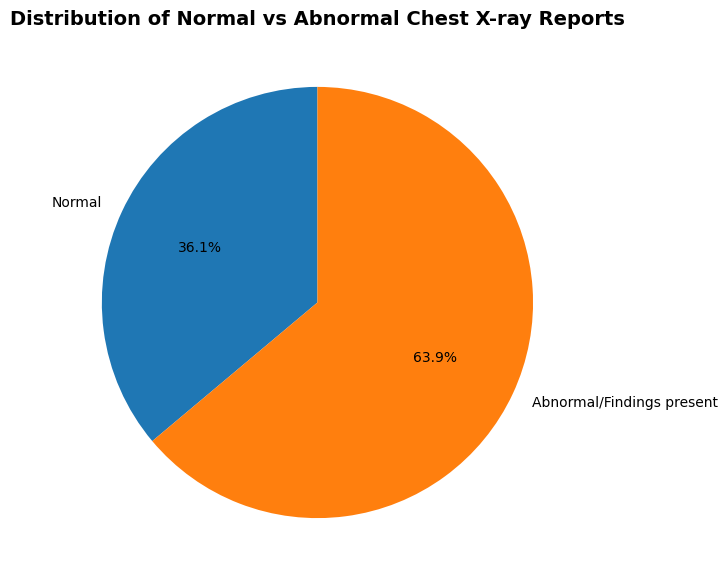

In [95]:
is_normal = (merged_df_clean["Problems"]=="normal").sum()

normal_counts = pd.Series({
    
    'Normal':is_normal, 
    
    'Abnormal/Findings present': len(merged_df_clean) - is_normal
})
plt.figure(figsize = (7,7))

plt.pie(normal_counts,
       labels = normal_counts.index,
        
        autopct='%1.1f%%',
       
        startangle = 90  
        
       )
plt.title('Distribution of Normal vs Abnormal Chest X-ray Reports', fontsize = 14, fontweight  = 'bold')
plt.show()


### Top 10 medical conditions

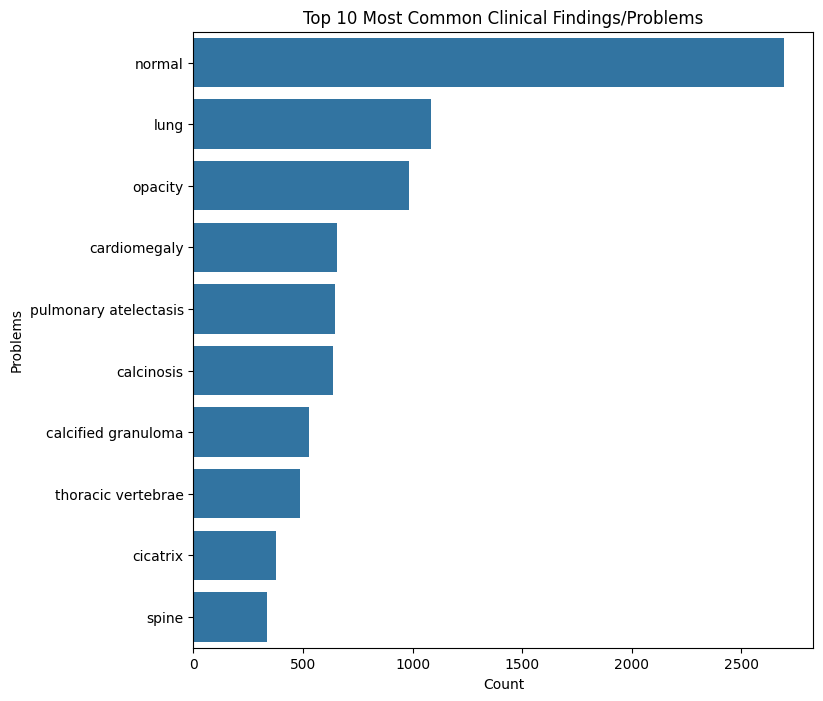

In [96]:
problem_counts = merged_df_clean["Problems"].dropna().str.split(';').explode().str.strip().value_counts()

plt.figure(figsize = (8,8))

sb.barplot(x=problem_counts.head(10).values, y = problem_counts.head(10).index)

plt.title('Top 10 Most Common Clinical Findings/Problems')

plt.xlabel('Count')

plt.show()

### Text Length analysis across columns

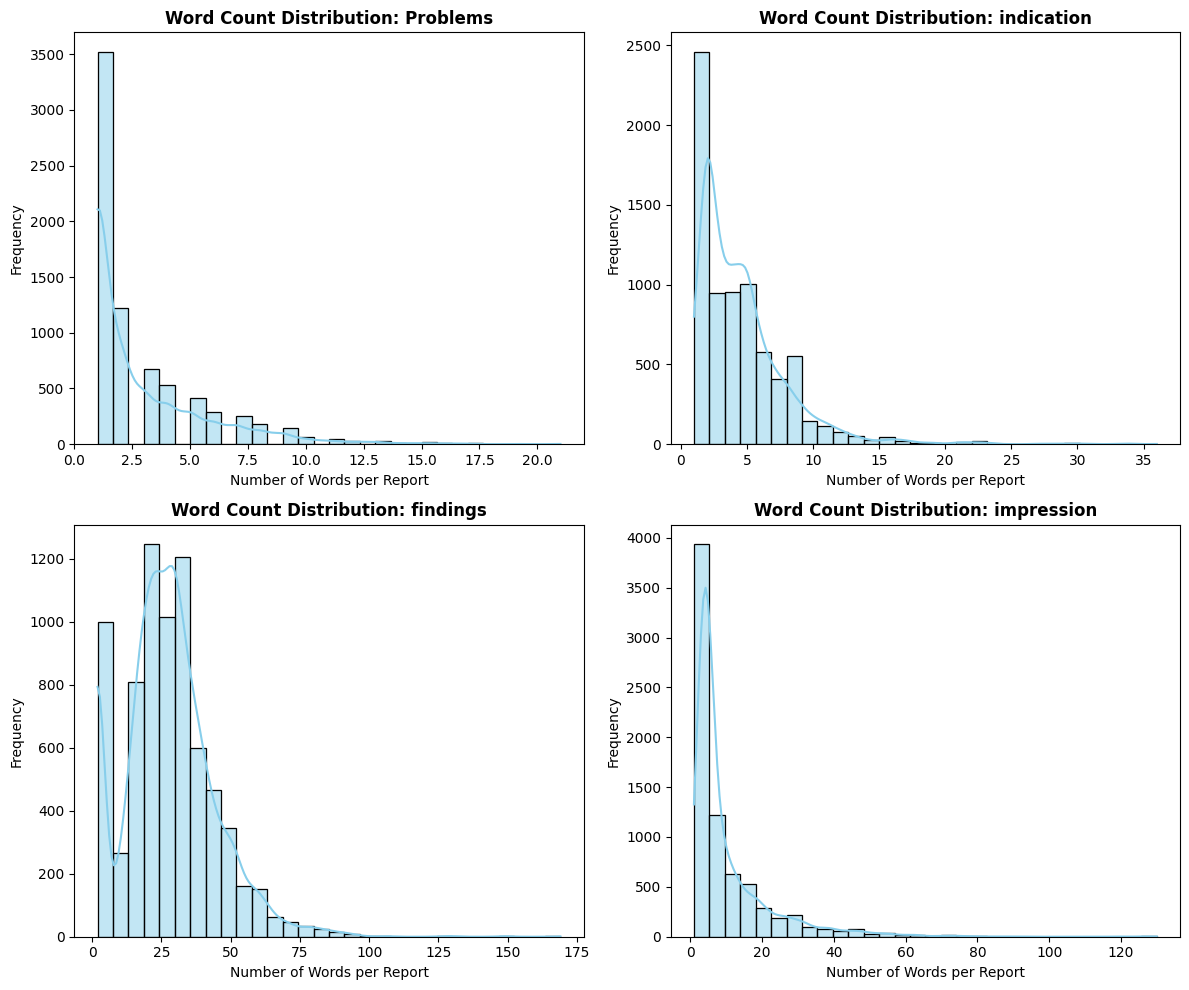

In [97]:
text_columns = ["Problems", "indication", "findings", "impression"]

fig, axs = plt.subplots(2,2, figsize = (12,10))

axs = axs.flatten()

for i, column in enumerate(text_columns):
    
    cleaned_series = (merged_df_clean[column].dropna().astype(str).str.replace(r'[^\w\s]', ' ', regex=True))
    
    word_counts  = cleaned_series.str.split().str.len()
    
    sb.histplot(word_counts, ax=axs[i], kde=True, color='skyblue', bins=30)
    
    axs[i].set_title(f'Word Count Distribution: {column}', fontsize=12, fontweight='bold')
    
    axs[i].set_xlabel('Number of Words per Report')
    
    axs[i].set_ylabel('Frequency')
    
plt.tight_layout()
plt.show()    
    

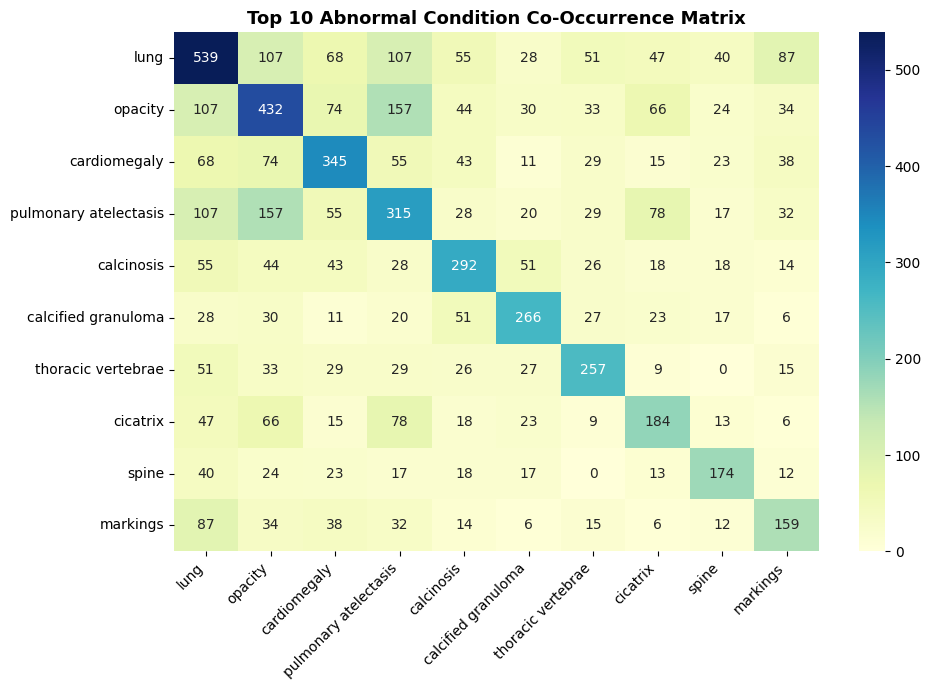

In [98]:
dummies = df_clean['Problems'].str.get_dummies(sep=';')

top_conditions = (

    dummies.drop(columns=['normal','no indexing'], errors = 'ignore').sum().nlargest(10).index

)

co_matrix = dummies[top_conditions]. T @ dummies[top_conditions]

plt.figure(figsize = (10,7))

sb.heatmap(co_matrix, annot=True, fmt='d', cmap='YlGnBu')

plt.title("Top 10 Abnormal Condition Co-Occurrence Matrix", fontsize = 13, fontweight = 'bold')

plt.xticks(rotation=45, ha='right')

plt.tight_layout()

plt.show()

### Measuring Correlation between Impression and Findings columns

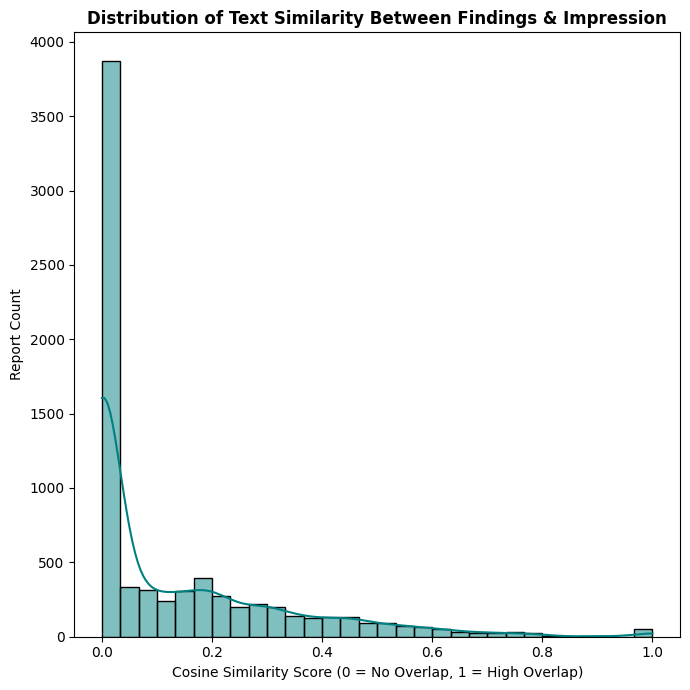

In [99]:
matched_text = merged_df_clean[['findings', 'impression']].dropna().copy()

vectorizer = TfidfVectorizer(stop_words='english')

vectorizer.fit(matched_text['findings'].tolist() + matched_text['impression'].tolist())

similarities = []

for f_text, i_text in zip(matched_text['findings'], matched_text['impression']):

    vec = vectorizer.transform([f_text,i_text])
    
    sim = cosine_similarity(vec[0],vec[1])[0][0]
    
    similarities.append(sim)

matched_text['cosine_similarity'] = similarities


plt.figure(figsize = (7,7))

sb.histplot(matched_text['cosine_similarity'], kde=True, bins=30, color='teal')

plt.title('Distribution of Text Similarity Between Findings & Impression', fontsize=12, fontweight='bold')

plt.xlabel('Cosine Similarity Score (0 = No Overlap, 1 = High Overlap)')

plt.ylabel('Report Count')

plt.tight_layout()

plt.show()

### Normal vs abnormal Image samples

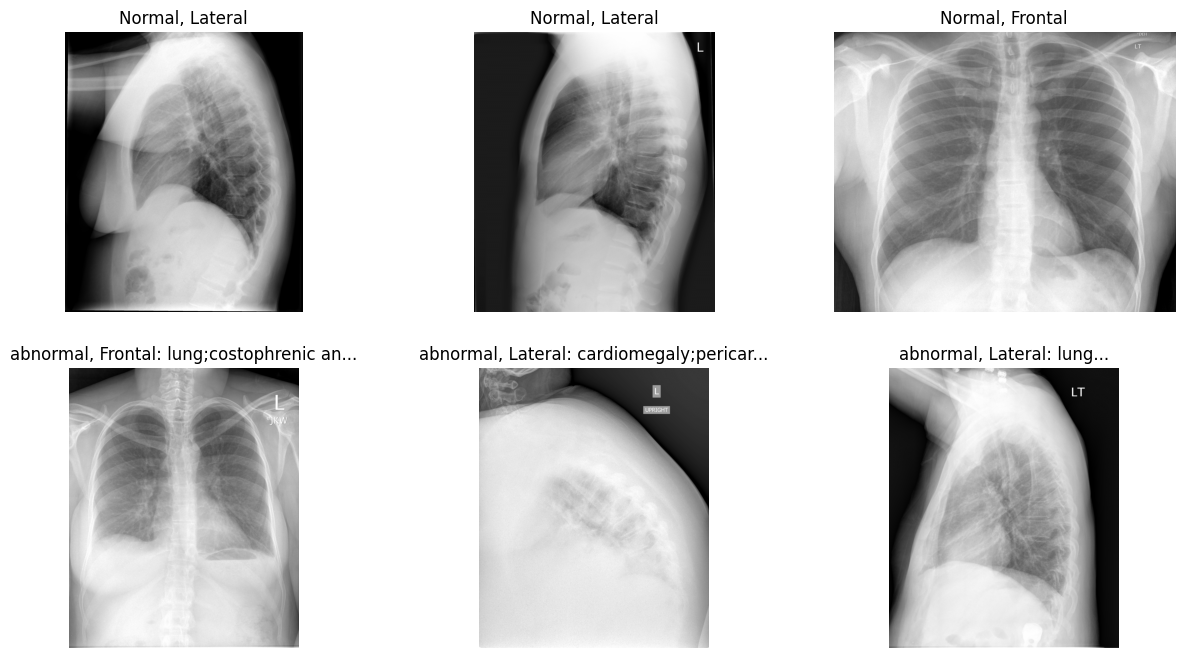

In [100]:
normal_samples = merged_df_clean[merged_df_clean['Problems']=='normal'].sample(3)

abnormal_samples = merged_df_clean[merged_df_clean['Problems']!='normal'].sample(3)

fig,axes = plt.subplots(2,3,figsize = (15,8))


for i,(_,row) in enumerate(normal_samples.iterrows()):

    img_path = image_folder/row['filename']
    
    img = Image.open(img_path)

    
    axes[0,i].imshow(img,cmap = 'gray')
    
    axes[0,i].set_title(f"Normal, {row["projection"]}")
    
    axes[0,i].axis("off")

for i,(_,row) in enumerate (abnormal_samples.iterrows()): 
    
    img_path = image_folder/row['filename']
    
    img = Image.open(img_path)
    
    axes[1,i].imshow(img, cmap = 'gray')
    
    axes[1,i].set_title(f"abnormal, {row["projection"]}: {str(row["Problems"])[:20]}...")
    
    axes[1,i].axis("off")
     
      

### Pixel intensity distribution (Normal vs Abnormal)

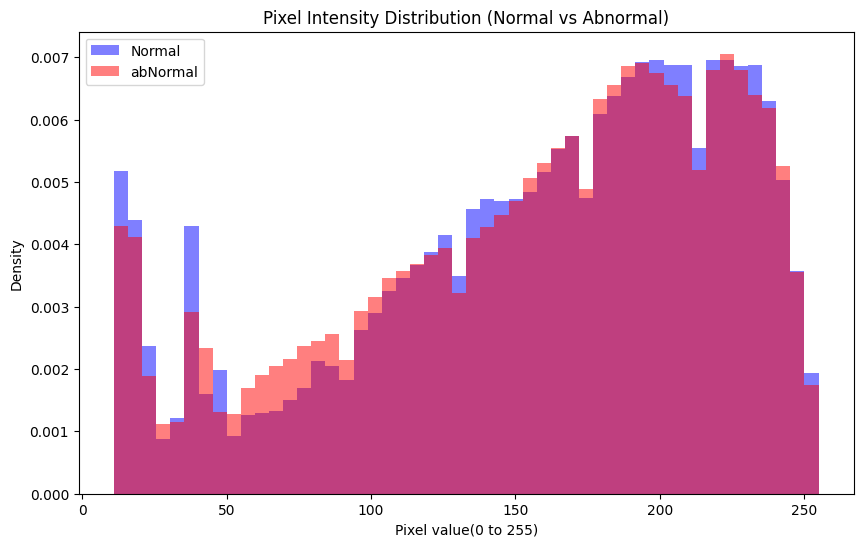

In [101]:
normal_samples = merged_df_clean[merged_df_clean['Problems']=='normal'].sample(50)['filename']
abnormal_samples = merged_df_clean[merged_df_clean['Problems']!='normal'].sample(50)['filename']

normal_pixels = []
abnormal_pixels = []
def get_body_pixels(img_array, threshold = 10):
    body_mask = img_array > threshold
    return img_array[body_mask]
    
for img_name in normal_samples: 
    img_path = image_folder/img_name
    img_array = np.array(Image.open(img_path).resize((256,256)))
    normal_pixels.extend(get_body_pixels(img_array).flatten())

for img_name in abnormal_samples:
    img_path = image_folder/img_name
    img_array = np.array(Image.open(img_path).resize((256,256)))
    abnormal_pixels.extend(get_body_pixels(img_array).flatten())

plt.figure(figsize = (10,6))

plt.hist(normal_pixels, bins = 50,alpha = 0.5, label = 'Normal', color= 'blue', density = True)
plt.hist(abnormal_pixels, bins = 50, alpha = 0.5, label = 'abNormal', color = 'red', density = True)
plt.title("Pixel Intensity Distribution (Normal vs Abnormal)")
plt.xlabel("Pixel value(0 to 255)")
plt.ylabel("Density")
plt.legend()
plt.show()

### Calculating the global pixel mean, normal pixel mean and abnormal pixel mean

In [102]:
def calculate_dataset_pixel_info(df, image_folder, sample_size = None, target_size=(256,256)):
    image_folder = Path(image_folder)
    normal_df = df[df["Problems"] == 'normal']
    abnormal_df = df[df['Problems'] != 'normal']

    if sample_size:
        normal_df = normal_df.sample(min(sample_size, len(normal_df)))
        abnormal_df = abnormal_df.sample(min(sample_size, len(abnormal_df)))
    def collect_pixels(sub_df):
        pixel_list = []
        for img_name in sub_df['filename']:
            img_path = image_folder/img_name
            img = Image.open(img_path).resize(target_size)
            pixel_list.append(np.array(img).flatten())
        return np.concatenate(pixel_list)

    normal_pixels = collect_pixels(normal_df)
    abnormal_pixels = collect_pixels(abnormal_df)

    global_pixels = np.concatenate([normal_pixels, abnormal_pixels])

    results = {
        'Global' : {
            'mean_255' : np.mean(global_pixels),
            'std_255' : np.std(global_pixels),
            'mean_norm': np.mean(global_pixels) / 255.0,
            'std_norm': np.std(global_pixels) / 255.0,
        },
        'Normal': {
            'mean_255': np.mean(normal_pixels),
            'std_255': np.std(normal_pixels),
            'mean_norm': np.mean(normal_pixels) / 255.0,
            'std_norm': np.std(normal_pixels) / 255.0,
        },
        'Abnormal': {
            'mean_255': np.mean(abnormal_pixels),
            'std_255': np.std(abnormal_pixels),
            'mean_norm': np.mean(abnormal_pixels) / 255.0,
            'std_norm': np.std(abnormal_pixels) / 255.0,
        }
    }
    summary_df = pd.DataFrame(results).T
    summary_df.columns = ['Mean (0-255)', 'Std (0-255)', 'Mean (0-1)', 'Std (0-1)']
    return summary_df

stats_summary = calculate_dataset_pixel_info(merged_df_clean, image_folder, sample_size = 200)
print(stats_summary)    
        

          Mean (0-255)  Std (0-255)  Mean (0-1)  Std (0-1)
Global      147.672850    71.747750    0.579109   0.281364
Normal      147.076501    71.194424    0.576771   0.279194
Abnormal    148.269198    72.291922    0.581448   0.283498


## Data Splitting

### Master Splitting the Data for the multimodal model
> To split on cases having a disease or not, making a synthesized column that tells us whether the patient is normal and abnormal to simplify splitting over the problem column due to having mutliple 

In [103]:
merged_df_clean['is_abnormal'] = merged_df_clean['Problems'].apply(lambda x: 'No' if str(x).strip().lower() == 'normal' else 'Yes')
merged_df_clean.head()

,uid,MeSH,Problems,image,indication,findings,impression,filename,projection,is_abnormal
0,1,normal,normal,xray chest pa and lateral,positive tb test,the cardiac silhouette and mediastinum size ar...,normal chest hiddenx,1_IM-0001-4001.dcm.png,Frontal,No
1,1,normal,normal,xray chest pa and lateral,positive tb test,the cardiac silhouette and mediastinum size ar...,normal chest hiddenx,1_IM-0001-3001.dcm.png,Lateral,No
2,2,cardiomegaly/borderline;pulmonary artery/enlarged,cardiomegaly;pulmonary artery,"chest, 2 views, frontal and lateral",preop bariatric surgery,borderline cardiomegaly midline sternotomy hid...,no acute pulmonary findings,2_IM-0652-1001.dcm.png,Frontal,Yes
3,2,cardiomegaly/borderline;pulmonary artery/enlarged,cardiomegaly;pulmonary artery,"chest, 2 views, frontal and lateral",preop bariatric surgery,borderline cardiomegaly midline sternotomy hid...,no acute pulmonary findings,2_IM-0652-2001.dcm.png,Lateral,Yes
4,3,normal,normal,xray chest pa and lateral,rib pain after a hidden hidden hidden steps th...,not provided,no displaced rib fractures pneumothorax or ple...,3_IM-1384-1001.dcm.png,Frontal,No


### Split the data using train_test_split
> Stratify the data on the is_abnormal column to just see 

In [146]:
case_df = merged_df_clean[['uid',"is_abnormal"]].drop_duplicates(
    subset="uid"
)
train_uids, test_uids = train_test_split(case_df["uid"], test_size = 0.2, random_state = 42, stratify = case_df['is_abnormal'])

train_df = merged_df_clean[merged_df_clean["uid"].isin(train_uids)].copy()
test_df = merged_df_clean[merged_df_clean["uid"].isin(test_uids)].copy()
print("Training rows:", train_df.shape)
print("Testing rows:", test_df.shape)
print("Training studies:", train_df["uid"].nunique())
print("Testing studies:", test_df["uid"].nunique())

Training rows: (5951, 10)
Testing rows: (1512, 10)
Training studies: 3080
Testing studies: 771


### Grouping each id to a list of images to prepare for training

In [160]:
def group_studies(df):
    return(
        df.groupby("uid").agg(filenames=("filename",list),
                             indication = ("indication", "first"),
                             Problems = ("Problems","first"),
                             is_abnormal = ("is_abnormal", "first")
                                       
    )).reset_index()

train_grouped = group_studies(train_df)
test_grouped = group_studies(test_df)

### Make a validation set

In [182]:
train_grouped, validation_grouped = train_test_split(train_grouped, test_size = 0.2, stratify = train_grouped["is_abnormal"], random_state = 42)


#### Make the problem column a list of diseases

In [183]:
def split_label (value):
    return [label.strip().lower() for label in str(value).split(';')]

y_train_labels = train_grouped["Problems"].apply(split_label)
y_test_labels = test_grouped["Problems"].apply(split_label)
y_val_labels = validation_grouped["Problems"].apply(split_label)


# Data Preprocessing

### Apply multi label encoding using Multi-label binarizer 

In [186]:
mlb = MultiLabelBinarizer()
Y_train = mlb.fit_transform(y_train_labels)
Y_test = mlb.transform(y_test_labels)
Y_val = mlb.transform(y_val_labels)

num_classes = len(mlb.classes_)

train_grouped["target"] = list(Y_train)
test_grouped["target"] = list(Y_test)
validation_grouped["target"] = list(Y_val)
print("Training_labels: ",Y_train.shape)
print("Test_labels:",Y_test.shape)
print("validation_labels: ",Y_val.shape)


Training_labels:  (329, 74)
Test_labels: (771, 74)
validation_labels:  (83, 74)


### Make the Image Preprocessing function

In [187]:
def process_image(image_path):
    image_size = 224
    image_bytes = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image_bytes, 
        channels = 1
    )
    image = tf.cast(image, tf.float32)

    image  = tf.image.resize_with_pad(
        image,
        target_height = image_size,
        target_width  = image_size
    )

    image = image / 255.0

    return image
    
    

### Text Tokenization

In [188]:

tokenizer = AutoTokenizer.from_pretrained("emilyalsentzer/Bio_ClinicalBERT")

def preprocess_text(text):
    
    tokens  = tokenizer(text, max_length = 100, padding = "max_length", return_tensors = "np")
    
    return {
        "input_ids":tokens["input_ids"][0].astype(np.int32),
        "attention_mask":tokens["attention_mask"][0].astype(np.int32)
    }


### Generate the record/patient format for training
> Generates a 5 image list as that was the maximum number of images for one record
> yields the images, tokens, and where the text is using attention_mask

In [189]:
max_images = 5
max_length = 100
img_size = (224, 224)
def patient_generator(df):
    for _ , row in df.iterrows():
        images = []
        for path in row["filenames"][:max_images]:
            full_path = f"{image_folder}/{path}"
            images.append(process_image(full_path))
        while len(images) < max_images : 
            images.append(tf.zeros((224,224,1),dtype = tf.float32))
        text_inputs = preprocess_text(row["indication"])
        target = np.asarray(row["target"],dtype = np.float32)
        
        yield({
            "images": tf.stack(images), 
            "input_ids":text_inputs["input_ids"],
            "attention_mask":text_inputs["attention_mask"]

        },
         target
        )

### Make the dataset and distribture to batches
> Every batch is made of 8 ids/patient records
> contains the images, input_ids, attention_mask and a tensor of float values to store the output

In [190]:
def make_dataset(df):
    dataset = tf.data.Dataset.from_generator(
        lambda: patient_generator(df),
        output_signature = ({"images":tf.TensorSpec(shape = (max_images, 224,224,1), dtype = tf.float32),
                            "input_ids": tf.TensorSpec(
                                shape = (max_length,),
                                dtype = tf.int32
                            ),
                             "attention_mask":tf.TensorSpec(
                                 shape = (max_length,),
                                 dtype = tf.int32
                             )},
                            tf.TensorSpec(shape=(num_classes,), dtype=tf.float32)
                           )
    )
    return dataset.batch(8).prefetch(tf.data.AUTOTUNE)
train_dataset = make_dataset(train_grouped)
val_dataset = make_dataset(validation_grouped)
test_dataset = make_dataset(test_grouped)

### Validate output shape

In [191]:
# Inspect one batch
for inputs, labels in train_dataset.take(1):
    for name, tensor in inputs.items():
        print(f"{name}:")
        print(f"  Shape: {tensor.shape}")
        print(f"  Dtype: {tensor.dtype}")

images:
  Shape: (8, 5, 224, 224, 1)
  Dtype: <dtype: 'float32'>
input_ids:
  Shape: (8, 100)
  Dtype: <dtype: 'int32'>
attention_mask:
  Shape: (8, 100)
  Dtype: <dtype: 'int32'>


### Image embeddings

In [170]:
!pip install kaggle
# (Make sure your kaggle.json token is uploaded)
!kaggle datasets download -d sinamhd9/chexnet-weights
!unzip -o chexnet-weights.zip



Dataset URL: https://www.kaggle.com/datasets/sinamhd9/chexnet-weights
License(s): unknown
chexnet-weights.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  chexnet-weights.zip
  inflating: brucechou1983_CheXNet_Keras_0.3.0_weights.h5  


In [192]:
img_size = 224

chexnet_base = DenseNet121(include_top=False, weights=None, input_shape=(img_size, img_size, 3))

chexnet_base.load_weights(
    "/kaggle/working/brucechou1983_CheXNet_Keras_0.3.0_weights.h5", 
    by_name=True, 
    skip_mismatch=True
)
chexnet_base.trainable = False

image_input = layers.Input(shape=(img_size, img_size, 1))


x = layers.Concatenate()([image_input, image_input, image_input])

x = chexnet_base(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

image_encoder = Model(image_input, x)
print("Model built successfully! Output shape:", image_encoder.output_shape)


Model built successfully! Output shape: (None, 1024)


In [193]:
def generate_embeddings(df):
    embeddings = []
    ids = []
    for _,row in tqdm(df.iterrows(), total = len(df),desc = "Extracting"):
        
        images_in_study = []
        
        for filename in row["filenames"][:5]:
            
            image_path = str(image_folder/filename)
            
            image = process_image(image_path)
            
            images_in_study.append(image)
            
        batch_images = tf.stack(images_in_study)
        image_embeddings = image_encoder.predict(batch_images, verbose = 0)
        study_embeddings = np.mean(image_embeddings, axis = 0)
        embeddings.append(study_embeddings)
        ids.append(row["uid"])
    return np.array(embeddings), np.array(ids)

In [194]:
x_train_images, train_ids = generate_embeddings(train_grouped)
x_val_images, valid_ids = generate_embeddings(validation_grouped)
x_test_images, test_ids = generate_embeddings(test_grouped)

Extracting: 100%|██████████| 771/771 [03:11<00:00,  4.03it/s]


In [142]:
print(x_train_images)
print(train_ids)

[[0.         0.00283234 0.00282066 ... 0.7441202  0.79766715 0.60568786]
 [0.         0.00245802 0.00209941 ... 0.7696439  0.7974957  0.6289674 ]
 [0.         0.00288343 0.00284082 ... 0.7418293  0.79778755 0.6030097 ]
 ...
 [0.         0.00279976 0.00243294 ... 0.7260101  0.79811066 0.5917464 ]
 [0.         0.00255692 0.00255627 ... 0.77134085 0.7975131  0.6270926 ]
 [0.         0.00263136 0.00277379 ... 0.77400386 0.7971405  0.62875795]]
[1426  991 1956 ... 3741 3328 1669]


In [145]:
train_df = pd.DataFrame(x_train_images)
val_df = pd.DataFrame(x_val_images)
test_df = pd.DataFrame(x_test_images)

# Add the corresponding IDs
train_df.insert(0, "uid", train_ids)
val_df.insert(0, "uid", valid_ids)
test_df.insert(0, "id", test_ids)

# Export to CSV
train_df.to_csv("train_embeddings.csv", index=False)
val_df.to_csv("val_embeddings.csv", index=False)
test_df.to_csv("test_embeddings.csv", index=False)

print("Embeddings exported successfully!")

Embeddings exported successfully!


In [ ]:
from google.colab import files

files.download("train_embeddings.csv")

files.download("test_embeddings.csv")